In [158]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [159]:
df = pd.read_csv('diabetes_prediction_dataset.csv')

In [160]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Explotatory data analysis

In [161]:
df.shape

(100000, 9)

In [162]:
df.columns

Index(['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history',
       'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes'],
      dtype='object')

In [163]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [164]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [165]:
df.isnull().sum()

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

In [166]:
df_clean = df.copy()

df_clean

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [167]:
df_clean.shape

(100000, 9)

In [168]:
df_clean.duplicated().sum()

3854

In [169]:
df_clean.drop_duplicates(inplace=True)


In [170]:
df_clean.shape

(96146, 9)

Visualization

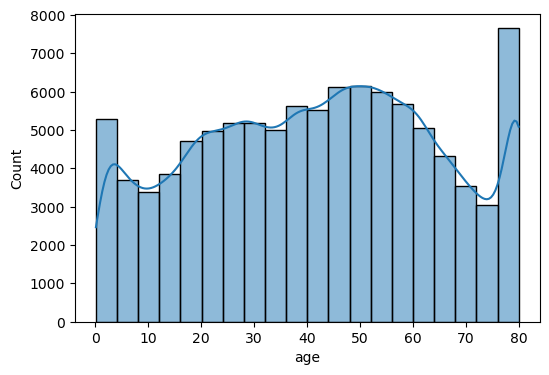

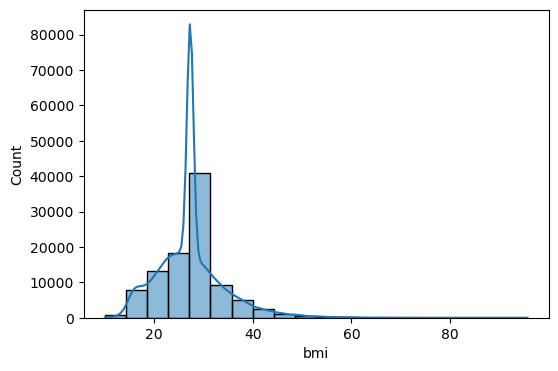

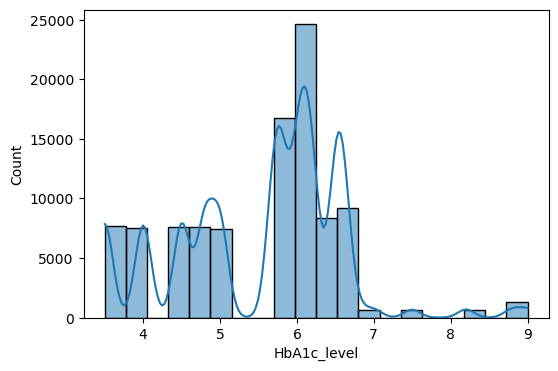

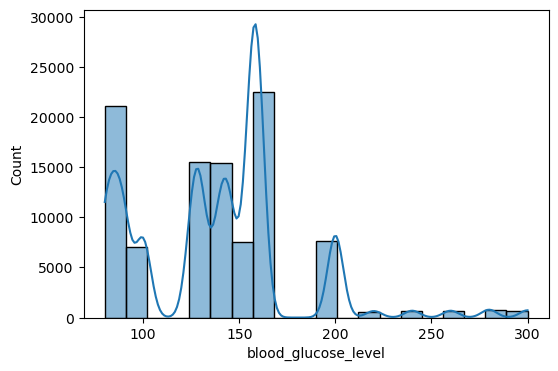

In [171]:
col_numbers = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
for col in col_numbers:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col], kde=True, bins=20)

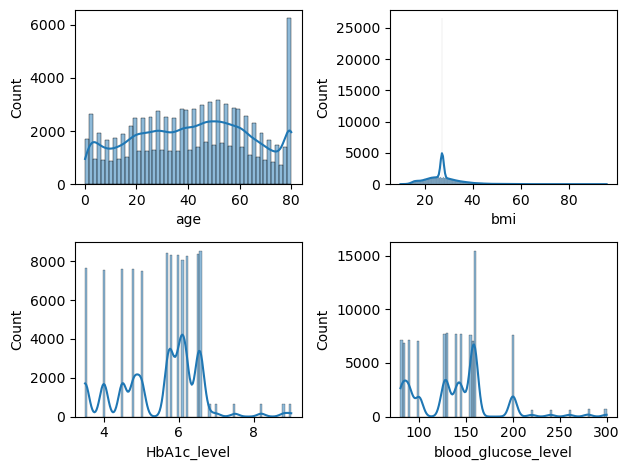

In [172]:
def plotting(var, num):
    plt.subplot(2,2,num)
    sns.histplot(df[var], kde=True)
plotting('age', 1)
plotting('bmi', 2)
plotting('HbA1c_level', 3)
plotting('blood_glucose_level', 4)
plt.tight_layout()

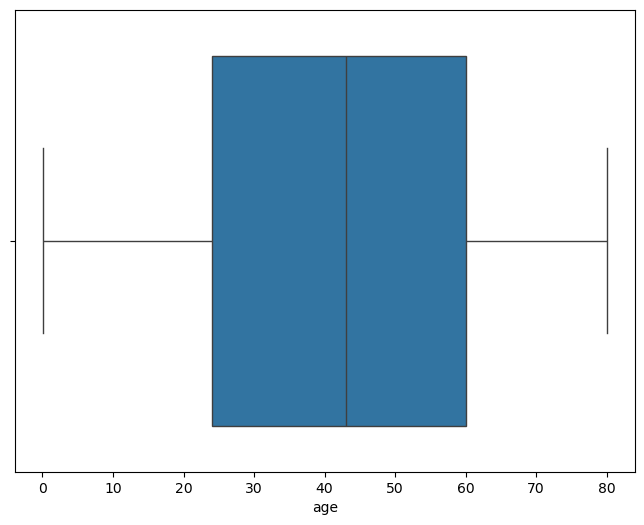

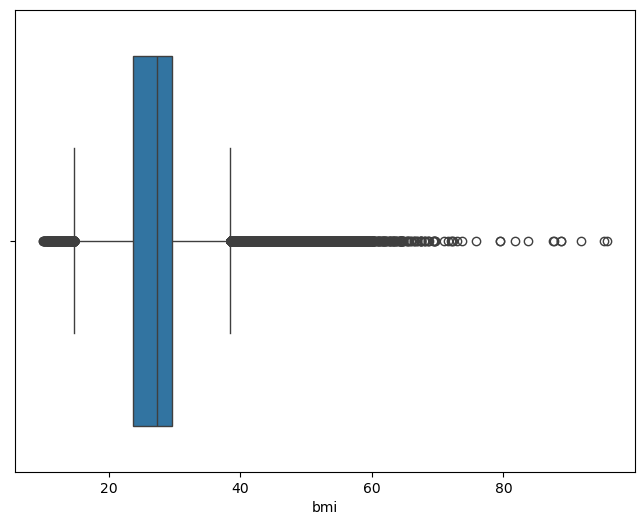

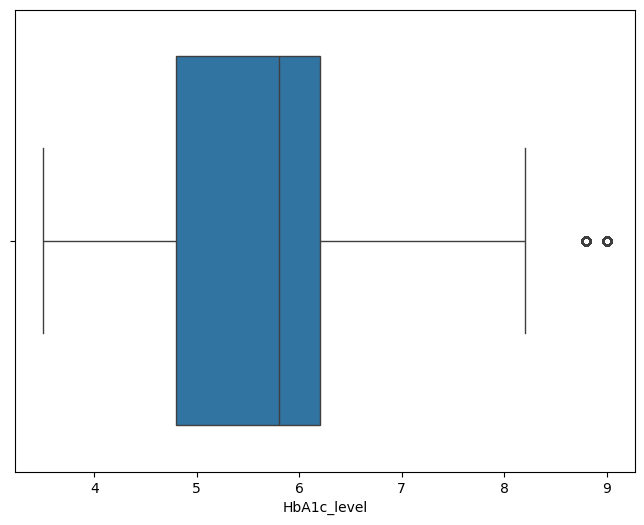

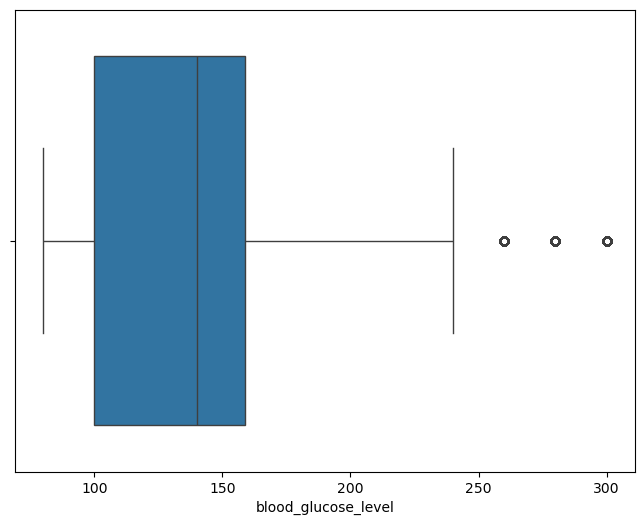

In [173]:
for col in col_numbers:
    plt.figure(figsize=(8,6))
    sns.boxplot(x=df[col])

<Axes: >

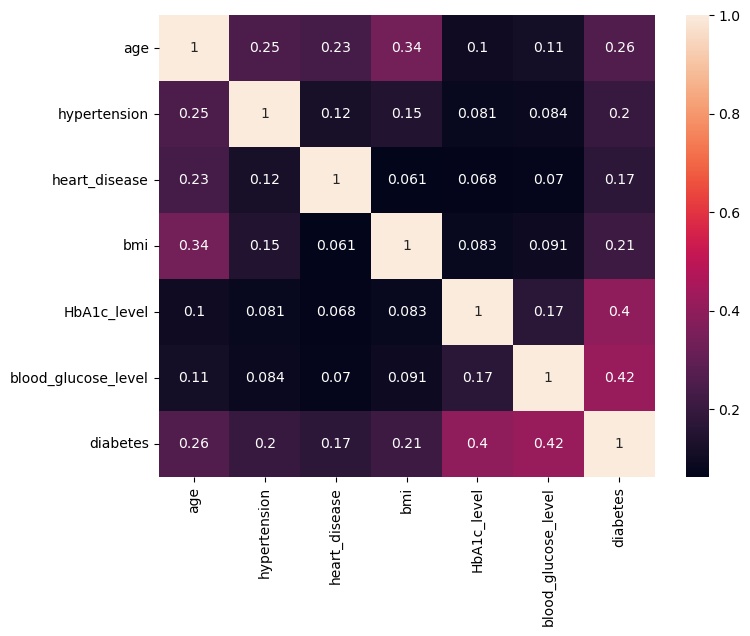

In [174]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True)

In [175]:
# BMI more than 80 is likely because of error so clean it
df_clean = df_clean[df_clean['bmi'] <= 80]

<Axes: xlabel='bmi', ylabel='Count'>

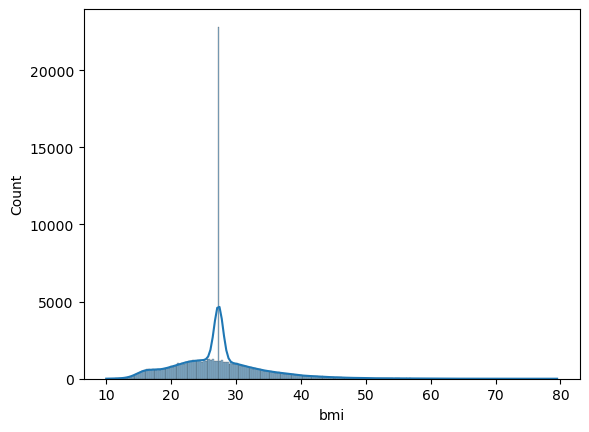

In [176]:
sns.histplot(df_clean['bmi'], kde=True)

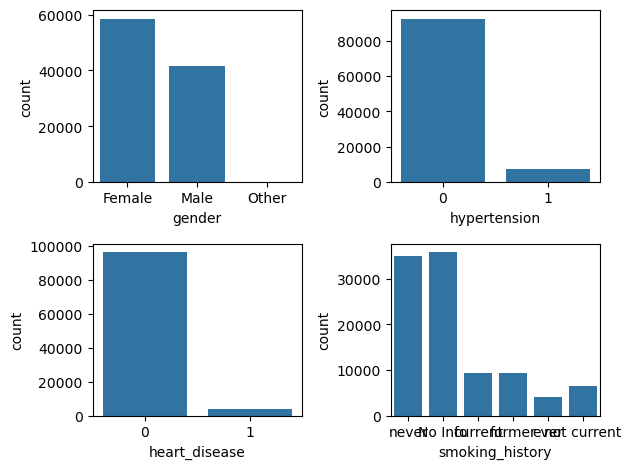

In [177]:
# for categorical value countplot is best
def cate_plotting(val, num):
    plt.subplot(2,2, num)
    sns.countplot(x=df[val])
cate_plotting('gender', 1)
cate_plotting('hypertension', 2)
cate_plotting('heart_disease', 3)
cate_plotting('smoking_history', 4)
plt.tight_layout()


In [178]:
df_clean['gender'].value_counts()

gender
Female    56158
Male      39961
Other        18
Name: count, dtype: int64

In [179]:
df_clean['smoking_history'].value_counts()

smoking_history
never          34394
No Info        32883
former          9298
current         9197
not current     6367
ever            3998
Name: count, dtype: int64

In [180]:
# In this case the value of No Info is very high so we will not delete it because they may have correlation with other features.
df_clean['smoking_history'] = df_clean['smoking_history'].replace('No Info', 'unknown')
df_clean['smoking_history'].value_counts()

smoking_history
never          34394
unknown        32883
former          9298
current         9197
not current     6367
ever            3998
Name: count, dtype: int64

In [181]:
df_clean

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,unknown,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,unknown,24.60,4.8,145,0
99996,Female,2.0,0,0,unknown,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [182]:
df_clean = pd.get_dummies(df_clean, columns=['gender', 'smoking_history'], drop_first=True)

In [183]:
df_clean

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,gender_Male,gender_Other,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current,smoking_history_unknown
0,80.0,0,1,25.19,6.6,140,0,False,False,False,False,True,False,False
1,54.0,0,0,27.32,6.6,80,0,False,False,False,False,False,False,True
2,28.0,0,0,27.32,5.7,158,0,True,False,False,False,True,False,False
3,36.0,0,0,23.45,5.0,155,0,False,False,False,False,False,False,False
4,76.0,1,1,20.14,4.8,155,0,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99994,36.0,0,0,24.60,4.8,145,0,False,False,False,False,False,False,True
99996,2.0,0,0,17.37,6.5,100,0,False,False,False,False,False,False,True
99997,66.0,0,0,27.83,5.7,155,0,True,False,False,True,False,False,False
99998,24.0,0,0,35.42,4.0,100,0,False,False,False,False,True,False,False


In [184]:
df_clean = df_clean.astype(int)

In [185]:
df_clean

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,gender_Male,gender_Other,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current,smoking_history_unknown
0,80,0,1,25,6,140,0,0,0,0,0,1,0,0
1,54,0,0,27,6,80,0,0,0,0,0,0,0,1
2,28,0,0,27,5,158,0,1,0,0,0,1,0,0
3,36,0,0,23,5,155,0,0,0,0,0,0,0,0
4,76,1,1,20,4,155,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99994,36,0,0,24,4,145,0,0,0,0,0,0,0,1
99996,2,0,0,17,6,100,0,0,0,0,0,0,0,1
99997,66,0,0,27,5,155,0,1,0,0,1,0,0,0
99998,24,0,0,35,4,100,0,0,0,0,0,1,0,0


In [210]:
df_clean.rename(columns={
  'smoking_history_not current' :'smoking_history_not_current'
},inplace=True)

In [187]:
# df_clean['bmi_category'] = pd.cut(
#     df_clean['bmi'],
#     bins = [0, 18.5, 24.9, 29.9, 34.9, 39.9, 80, float('inf')],
#     labels = [
#     "Underweight",
#     "Normal weight",
#     "Overweight",
#     "Obese (Class I)",
#     "Obese (Class II)",
#     "Obese (Class III)",
#     "Extreme obesity"
# ])

In [188]:
# df_clean

In [189]:
# df_clean = pd.get_dummies(df_clean, columns=['bmi_category'], drop_first=True)

In [190]:
# df_clean

In [191]:
# df_clean = df_clean.astype(int)

In [192]:
# df_clean

In [193]:
# df_clean['HbA1c_level_category'] = pd.cut(
#     df_clean['HbA1c_level'],
#     bins=[0, 5.7, 6.4,float('inf')],
# labels=['Normal', 'Prediabetes', 'Diabetes']
# )

In [194]:
# df_clean

In [195]:
# df_clean = pd.get_dummies(df_clean, columns=['HbA1c_level_category'], drop_first=True)

In [196]:
# df_clean

In [197]:
# df_clean = df_clean.astype(int)

In [198]:
# df_clean

In [199]:
# For blood glucose level we have two conditions:
# 1. fasting(before meal)
# 2. post_meal(2 hr after meal)
# we will go for fasting daibetes


# df_clean['blood_glucose_level_category']= pd.cut(
#     df_clean['blood_glucose_level'],
#     bins=[0, 70, 100, 125, float('inf')],
#     labels=['Low', 'Normal', 'Prediabetes', 'Diabetes']
# )

In [200]:
# df_clean

In [201]:
# df_clean = pd.get_dummies(df_clean, columns=['blood_glucose_level_category'], drop_first=True)

In [202]:
# df_clean

In [203]:
# df_clean = df_clean.astype(int)

In [211]:
df_clean

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,gender_Male,gender_Other,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not_current,smoking_history_unknown
0,1.699825,0,1,-0.276348,0.781467,0.043575,0,0,0,0,0,1,0,0
1,0.543355,0,0,0.020082,0.781467,-1.423154,0,0,0,0,0,0,0,1
2,-0.613115,0,0,0.020082,-0.124376,0.483593,0,1,0,0,0,1,0,0
3,-0.257278,0,0,-0.572778,-0.124376,0.410257,0,0,0,0,0,0,0,0
4,1.521907,1,1,-1.017423,-1.030218,0.410257,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99994,-0.257278,0,0,-0.424563,-1.030218,0.165802,0,0,0,0,0,0,0,1
99996,-1.769584,0,0,-1.462068,0.781467,-0.934245,0,0,0,0,0,0,0,1
99997,1.077111,0,0,0.020082,-0.124376,0.410257,0,1,0,0,1,0,0,0
99998,-0.791033,0,0,1.205803,-1.030218,-0.934245,0,0,0,0,0,1,0,0


In [205]:
# df_clean['age'].dtypes

Feature Scaling

In [212]:
from sklearn.preprocessing import StandardScaler
cols=['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
scalar = StandardScaler()
df_clean[cols] = scalar.fit_transform(df_clean[cols])

In [213]:
df_clean

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes,gender_Male,gender_Other,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not_current,smoking_history_unknown
0,1.699825,0,1,-0.276348,0.781467,0.043575,0,0,0,0,0,1,0,0
1,0.543355,0,0,0.020082,0.781467,-1.423154,0,0,0,0,0,0,0,1
2,-0.613115,0,0,0.020082,-0.124376,0.483593,0,1,0,0,0,1,0,0
3,-0.257278,0,0,-0.572778,-0.124376,0.410257,0,0,0,0,0,0,0,0
4,1.521907,1,1,-1.017423,-1.030218,0.410257,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99994,-0.257278,0,0,-0.424563,-1.030218,0.165802,0,0,0,0,0,0,0,1
99996,-1.769584,0,0,-1.462068,0.781467,-0.934245,0,0,0,0,0,0,0,1
99997,1.077111,0,0,0.020082,-0.124376,0.410257,0,1,0,0,1,0,0,0
99998,-0.791033,0,0,1.205803,-1.030218,-0.934245,0,0,0,0,0,1,0,0


In [214]:
df_clean.columns

Index(['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level',
       'blood_glucose_level', 'diabetes', 'gender_Male', 'gender_Other',
       'smoking_history_ever', 'smoking_history_former',
       'smoking_history_never', 'smoking_history_not_current',
       'smoking_history_unknown'],
      dtype='object')

In [226]:
from scipy.stats import pearsonr

selected_features = ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_Male', 'gender_Other', 'smoking_history_ever', 'smoking_history_former','smoking_history_never', 'smoking_history_not_current','smoking_history_unknown']

correlation = {}

for feature in selected_features:
    correlation[feature] = pearsonr(
        df_clean[feature],
        df_clean['diabetes']
    )[0]

correlation_df = pd.DataFrame(list(correlation.items()), columns=['Feature', 'Pearson Correlation'])

correlation_df.sort_values(by='Pearson Correlation', ascending=False)

,Feature,Pearson Correlation
5,blood_glucose_level,0.424301
4,HbA1c_level,0.392830
0,age,0.264868
3,bmi,0.214542
1,hypertension,0.195766
2,heart_disease,0.170756
9,smoking_history_former,0.095426
6,gender_Male,0.037925
10,smoking_history_never,0.023075
8,smoking_history_ever,0.021935


In [216]:
cate_faetures = ['hypertension', 'heart_disease', 'gender_Male', 'gender_Other', 'smoking_history_ever', 'smoking_history_former','smoking_history_never', 'smoking_history_not_current','smoking_history_unknown']

In [218]:
# Gor chi-square test
from scipy.stats import chi2_contingency
alpha = 0.05

chi_results = {}

for col in cate_faetures:
    contingency = pd.crosstab(
        df_clean[col], df_clean['diabetes']
    )

    chi2_stat, p_val, _, _ = chi2_contingency(contingency)

    decision = (
        "Reject Null (Keep Feature)" if p_val < alpha else "Accept Null (Drop Feature)"
    )
    chi_results[col] ={
        'chi_statistics': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    } 

chi2_df = pd.DataFrame(chi_results).T

chi2_df = chi2_df.sort_values(by='p_value')
chi2_df

,chi_statistics,p_value,Decision
hypertension,3681.809855,0.0,Reject Null (Keep Feature)
heart_disease,2800.081795,0.0,Reject Null (Keep Feature)
smoking_history_unknown,1216.22297,0.0,Reject Null (Keep Feature)
smoking_history_former,874.289738,0.0,Reject Null (Keep Feature)
gender_Male,138.000988,0.0,Reject Null (Keep Feature)
smoking_history_never,51.020423,0.0,Reject Null (Keep Feature)
smoking_history_ever,45.869776,0.0,Reject Null (Keep Feature)
smoking_history_not_current,34.240944,0.0,Reject Null (Keep Feature)
gender_Other,0.81724,0.365988,Accept Null (Drop Feature)


In [228]:
final_df = df_clean[['age','blood_glucose_level', 'bmi', 'HbA1c_level','hypertension', 'heart_disease', 'smoking_history_unknown', 'smoking_history_unknown', 'smoking_history_former', 'gender_Male', 'smoking_history_never', 'smoking_history_ever', 'smoking_history_not_current']]

In [229]:
final_df

,age,blood_glucose_level,bmi,HbA1c_level,hypertension,heart_disease,smoking_history_unknown,smoking_history_unknown,smoking_history_former,gender_Male,smoking_history_never,smoking_history_ever,smoking_history_not_current
0,1.699825,0.043575,-0.276348,0.781467,0,1,0,0,0,0,1,0,0
1,0.543355,-1.423154,0.020082,0.781467,0,0,1,1,0,0,0,0,0
2,-0.613115,0.483593,0.020082,-0.124376,0,0,0,0,0,1,1,0,0
3,-0.257278,0.410257,-0.572778,-0.124376,0,0,0,0,0,0,0,0,0
4,1.521907,0.410257,-1.017423,-1.030218,1,1,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99994,-0.257278,0.165802,-0.424563,-1.030218,0,0,1,1,0,0,0,0,0
99996,-1.769584,-0.934245,-1.462068,0.781467,0,0,1,1,0,0,0,0,0
99997,1.077111,0.410257,0.020082,-0.124376,0,0,0,0,1,1,0,0,0
99998,-0.791033,-0.934245,1.205803,-1.030218,0,0,0,0,0,0,1,0,0
